In [ ]:
!pip install openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [ ]:
import pandas as pd

# Using the existing, valid file in your workspace
try:
    df = pd.read_excel("Online Retail.xlsx", engine="openpyxl")
except Exception as e:
    print(f"Could not load 'Online Retail.xlsx': {e}")
    # Fallback in case we need to load the lowercase one
    df = pd.read_excel("online_retail.xlsx", engine="openpyxl")

print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Remove missing customer IDs
df = df.dropna(subset=["CustomerID"])

# Remove cancelled orders
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid quantity and price
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate total purchase amount
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print(df.shape)
df.head()

(397884, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Apply log transformation
rfm_log = np.log1p(rfm)

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

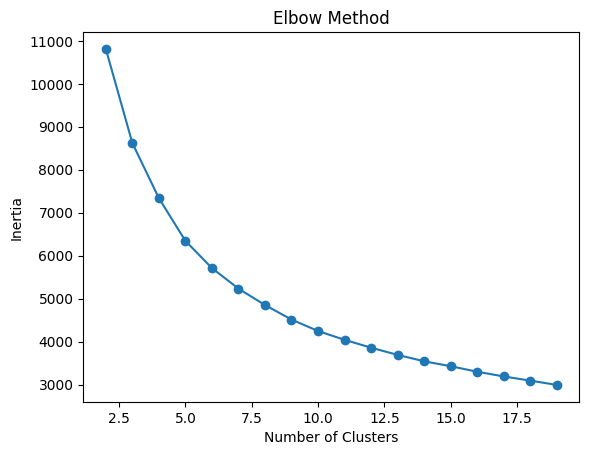

In [ ]:
inertia = []

for k in range(2, 20):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.plot(range(2, 20), inertia, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(rfm["KMeans_Cluster"].value_counts())

score = silhouette_score(X_scaled, rfm["KMeans_Cluster"])

print("Silhouette Score:", score)

KMeans_Cluster
3    1084
2    1084
4    1000
0     734
1     436
Name: count, dtype: int64
Silhouette Score: 0.2527704927921214


In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=10)

dbscan_labels = dbscan.fit_predict(X_scaled)

mask = dbscan_labels != -1

X_clean = X_scaled[mask]
labels_clean = dbscan_labels[mask]

score = silhouette_score(X_clean, labels_clean)

print("DBSCAN Silhouette Score:", score)
print(pd.Series(dbscan_labels).value_counts())

DBSCAN Silhouette Score: 0.23133242894231526
 0    2440
 1    1407
-1     491
Name: count, dtype: int64


In [ ]:
rfm["DBSCAN_Cluster"] = dbscan_labels

print(
    rfm[rfm["DBSCAN_Cluster"] != -1]
    .groupby("DBSCAN_Cluster")[["Recency", "Frequency", "Monetary"]]
    .mean()
)

                   Recency  Frequency     Monetary
DBSCAN_Cluster                                    
0                62.979918   4.446311  1486.473489
1               161.770434   1.000000   327.208515


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

rfm["PCA1"] = X_pca[:, 0]
rfm["PCA2"] = X_pca[:, 1]

print("Explained Variance:",
      pca.explained_variance_ratio_.sum())

Explained Variance: 0.8151319025138251


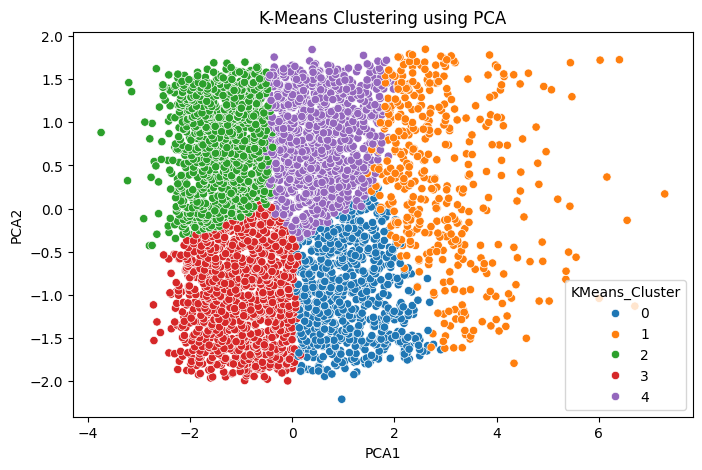

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Cluster",
    palette="tab10"
)

plt.title("K-Means Clustering using PCA")
plt.show()

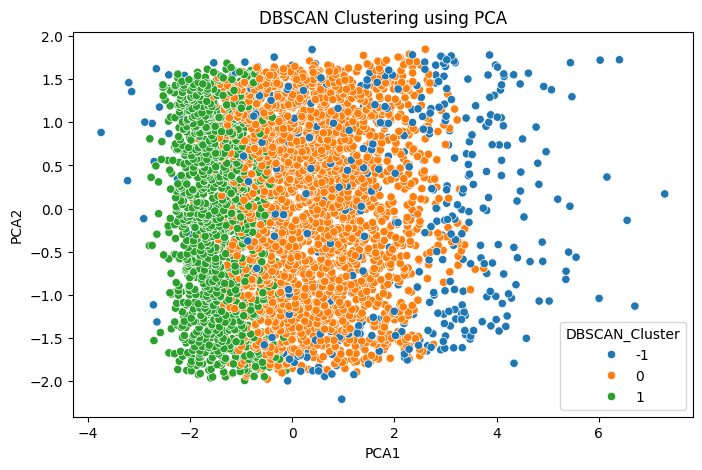

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x="PCA1",
    y="PCA2",
    hue="DBSCAN_Cluster",
    palette="tab10"
)

plt.title("DBSCAN Clustering using PCA")
plt.show()

In [ ]:
sample = rfm.sample(
    n=min(2000, len(rfm)),
    random_state=42
)

indices = sample.index

X_sample = X_scaled[indices]

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=min(30, max(5, (len(sample)-1)//3)),
    init="pca"
)

X_tsne = tsne.fit_transform(X_sample)

sample["tSNE1"] = X_tsne[:, 0]
sample["tSNE2"] = X_tsne[:, 1]

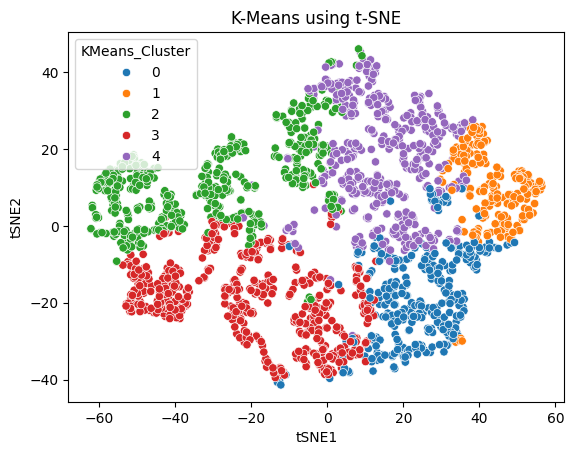

In [ ]:
sns.scatterplot(
    data=sample,
    x="tSNE1",
    y="tSNE2",
    hue="KMeans_Cluster",
    palette="tab10"
)

plt.title("K-Means using t-SNE")
plt.show()

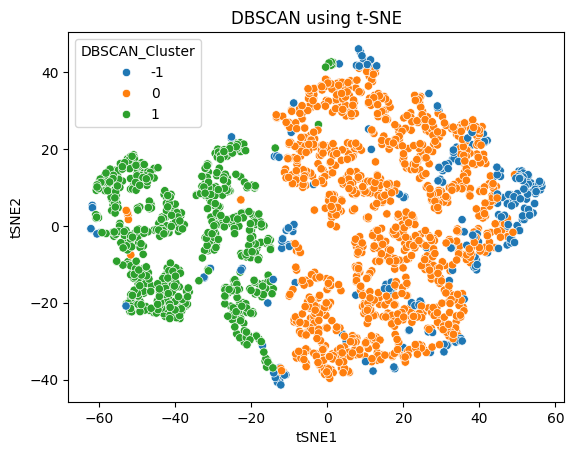

In [ ]:
sns.scatterplot(
    data=sample,
    x="tSNE1",
    y="tSNE2",
    hue="DBSCAN_Cluster",
    palette="tab10"
)

plt.title("DBSCAN using t-SNE")
plt.show()

In [ ]:
cluster_analysis = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

print(cluster_analysis.round(2))

                Recency  Frequency  Monetary
KMeans_Cluster                              
0                 30.91       4.99   2329.28
1                 12.38      17.95  11349.85
2                163.62       1.35    323.03
3                140.95       1.54    506.93
4                 43.18       3.91   1353.51


In [ ]:
overall = rfm[["Recency", "Frequency", "Monetary"]].mean()

for cluster, row in cluster_analysis.iterrows():

    print("\nCluster:", cluster)

    if row["Recency"] < overall["Recency"] and row["Frequency"] > overall["Frequency"]:

        print("Persona: Loyal Customers")
        print("Strategy: Give loyalty points and VIP rewards.")

    elif row["Recency"] > overall["Recency"]:

        print("Persona: At-Risk Customers")
        print("Strategy: Send discounts and win-back emails.")

    elif row["Frequency"] < overall["Frequency"]:

        print("Persona: Occasional Customers")
        print("Strategy: Give second-purchase coupons.")

    else:

        print("Persona: Potential Loyalists")
        print("Strategy: Provide personalized recommendations.")


Cluster: 0
Persona: Loyal Customers
Strategy: Give loyalty points and VIP rewards.

Cluster: 1
Persona: Loyal Customers
Strategy: Give loyalty points and VIP rewards.

Cluster: 2
Persona: At-Risk Customers
Strategy: Send discounts and win-back emails.

Cluster: 3
Persona: At-Risk Customers
Strategy: Send discounts and win-back emails.

Cluster: 4
Persona: Occasional Customers
Strategy: Give second-purchase coupons.


In [ ]:
rfm.to_csv("customer_segments.csv", index=False)

cluster_analysis.to_csv("cluster_analysis.csv")

print("Files saved successfully!")

Files saved successfully!
